**Introduction**

Today, various FinBERT models still form the basis of risk management in the financial sector, where there is a residual question - is small really beautiful (Kim *et al*., 2024) Phi is pushing the boundaries of making large language models small as well as powerful, filling the gap that still exists between accuracy of newer LLMs and inference speed and low cost of open-access models. Therefore these models were researched to determine where the niche in the financial market was for our proposed agentic approach with Claude.

**Approach**

JPMorgan (JPM) was used as a financially stable example, but with some hurdles that were managed well by the bank in the quarters analysed. Credit Suisse (CS) was used as the stress-test in its approach to collapse (Market Research_Part 2).

The approach is documented throughout this notebook, with justifications. It is fully summarised, with the results, at the end of the notebook "Market Research_Part 2" where the output from both banks is also compared, enabling conclusions to be drawn.

**Scalability**

A100 GPU was used to accelerate the processing speed of the models explored here and would be needed in the field, particularly for computationally intensive tasks like inference and training.

**Installs**

In [ ]:
# Install numpy first to avoid ABI mismatches
!pip install numpy==1.26.4

# Reinstall other core packages safely
!pip install scipy
!pip install gensim
!pip install pyldavis
!pip install pymupdf

# Install compatible torch + torchvision (CPU version to avoid CUDA mismatches)
!pip install torch==2.2.2 torchvision==0.17.2 --index-url https://download.pytorch.org/whl/cpu

# Install BERTopic stack
!pip install transformers==4.40.2 accelerate==0.27.2 sentence-transformers==2.5.1
!pip install bertopic==0.16.4

Looking in indexes: https://download.pytorch.org/whl/cpu


**Library Imports**

In [ ]:
import matplotlib.pyplot as plt
import spacy
import fitz
import os
import re
import nltk
import gdown
import numpy as np
import pandas as pd
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download("wordnet")

from nltk.stem import WordNetLemmatizer
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
import string
import re

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import pipeline

from sentence_transformers import SentenceTransformer
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from hdbscan import HDBSCAN
from tqdm import tqdm
from nltk.corpus import stopwords
import torch as torch

from gensim.models import LdaModel
from gensim.corpora import Dictionary
import nltk
import gensim
import pyLDAvis.gensim_models as gensimvis
import pyLDAvis
import string
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk
nltk.download('vader_lexicon')
from collections import Counter

from tqdm import tqdm

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


**Downloads Q1 2021-Q2 2023**

Q1 2021 - Q2 2023 were downloaded as the train set, as proposed in initial project scope. Also, specific events were identified in the history of JPMorgan that could be used in manual validation.

In [ ]:
# List of shared Google Drive links (use shareable links)
drive_links = ["https://drive.google.com/file/d/125LSVly44WP3wdzwyQJakww0D5YzNnS6/view?usp=sharing",
               "https://drive.google.com/file/d/14uE1qoEKpcVk0p3W6bdNlt5BS1P7mwPG/view?usp=sharing",
               "https://drive.google.com/file/d/1B7pGdLYRzriCuzTk_-dGmXqw8Jfa-PJv/view?usp=sharing",
               "https://drive.google.com/file/d/1CHvuukVzjLrI7vR6_AEaCJJTBk88igPY/view?usp=sharing",
               "https://drive.google.com/file/d/1F6GmtZu_gqcBq7SG0JhUYcVCAvThIzRO/view?usp=sharing",
               "https://drive.google.com/file/d/1I1Y4QdDl2K7q7JJTS8f7hKq9L3zPYhcs/view?usp=sharing",
               "https://drive.google.com/file/d/1Iw6C0Bkrd6Z9ofDH2FBOs8nmUKfwRscs/view?usp=sharing",
               "https://drive.google.com/file/d/1JXR3o3jdq-BGD3xWmA3lIdTcHcR3mVq6/view?usp=sharing",
               "https://drive.google.com/file/d/1MMjhZ1AHrlQMYxoojeuWlSeJLXNNbDd0/view?usp=sharing",
               "https://drive.google.com/file/d/1MVF9MUWBz9XWVtOqQYK_H4NCOoL67pBr/view?usp=sharing",
               "https://drive.google.com/file/d/1NmQFOuvOAmIoHnAI6EjyOtNq8fnrFAWp/view?usp=sharing",
               "https://drive.google.com/file/d/1RbUDKhPtoojZr1w0NdbWQ0U3W7_hLkp2/view?usp=sharing",
               "https://drive.google.com/file/d/1VKUb4X9eUMt6RaTxSpqI1eNmK1aAUg-Z/view?usp=sharing",
               "https://drive.google.com/file/d/1Yz_HwBdpie3SXAdKm9JxBuNsJnz9E0ly/view?usp=sharing",
               "https://drive.google.com/file/d/1_Lw-GlhzQODJKFzlWzJgtrLiUHWGJJFV/view?usp=sharing",
               "https://drive.google.com/file/d/1_NWFywaejctmMgQNi5lGUwOPgn3n0kue/view?usp=sharing",
               "https://drive.google.com/file/d/1aGMqhj2qjYKCibdhTjyuhQgdyyty9Aak/view?usp=sharing",
               "https://drive.google.com/file/d/1b60OOpXEhNJ9JMYJBKDcmQ_OjJgnyfZI/view?usp=sharing",
               "https://drive.google.com/file/d/1dqC2Hi0xdTDOsYSV0Xr4XjFrFu7g01Lz/view?usp=sharing",
               "https://drive.google.com/file/d/1dw-oo0sTHBx_39f4WVPBskDXyNq0f92I/view?usp=sharing",
               "https://drive.google.com/file/d/1erHDmateaHe-cgaGPMJCWpRqrPW46UZb/view?usp=sharing",
               "https://drive.google.com/file/d/1hEXW0ZeSPpwWGRIVUm2FEZcq0QFFQfSh/view?usp=sharing",
               "https://drive.google.com/file/d/1iJ9KIC5hc_zxSIgONEPjq834sjOBzCf0/view?usp=sharing",
               "https://drive.google.com/file/d/1ieZpKb4m8-MR9y57MLBOxJVnms1LshJv/view?usp=sharing",
               "https://drive.google.com/file/d/1j-y8DCfA0Kb8PZ6LBR0LzQA5z7xI5eO7/view?usp=sharing",
               "https://drive.google.com/file/d/1kCDY7kaAKQn6GlCCaadvIV3GhRWiysJs/view?usp=sharing",
               "https://drive.google.com/file/d/1kkZCaeiuYRWMe592hIXLk2o0qdVfRZ-U/view?usp=sharing",
               "https://drive.google.com/file/d/1l4S-f60Pf5evvByj_cKLCayq1fVplwoU/view?usp=sharing",
               "https://drive.google.com/file/d/1m4pk5TOFAfo19Zdgu-YXkUmKE4BBG399/view?usp=sharing",
               "https://drive.google.com/file/d/1nCqB1W2N5U0EPOYizcIQ7qIAOzthOXAP/view?usp=sharing",
               "https://drive.google.com/file/d/1pTL5RTtcC7rKwspLKlbSkczYDu-dbmRO/view?usp=sharing",
               "https://drive.google.com/file/d/1t9XJdx5OM4jPTh3bn4_1ldHXr6wWKA9R/view?usp=sharing",
               "https://drive.google.com/file/d/1u72j0G_QpAbFUILyKZQwCc_GzDYkWGZd/view?usp=sharing",
               "https://drive.google.com/file/d/1wq8dVK_4yQ3ZNnHHFxvTjHBC5koXKANX/view?usp=sharing",
               "https://drive.google.com/file/d/1x8P_NR3R8CmeDlhNJOTDvkmZx2EMvHO_/view?usp=sharing",
               "https://drive.google.com/file/d/1yYMeC8n90Nx133cqzTCRk_x-8mQKq4hW/view?usp=sharing"
]

# Output directory
download_dir = "transcripts"
os.makedirs(download_dir, exist_ok=True)

# Download from drive
def download_from_drive(url, output_path):
    try:
        gdown.download(url, output_path, fuzzy=True)
        print(f"Downloaded: {output_path}")
    except Exception as e:
        print(f"Failed to download {url}: {e}")

# Extract text from pdf
def extract_text_from_pdf(pdf_path):
    doc = fitz.open(pdf_path)
    full_text = ""
    for page in doc:
        full_text += page.get_text()
    return full_text

# Iterate through all pdfs/transcripts
all_texts = []
all_filenames = []

for i, url in enumerate(tqdm(drive_links, desc="Downloading transcripts")):
    filename = f"Transcript_{i+1}.pdf"
    output_path = os.path.join(download_dir, filename)

    # Download the PDF
    download_from_drive(url, output_path)

    # Verify and extract
    if os.path.exists(output_path):
        print(f"Size: {os.path.getsize(output_path)} bytes")

        text = extract_text_from_pdf(output_path)
        all_texts.append(text)
        all_filenames.append(filename)

        print("Text preview:", text[:500], "\n" + "-"*80)

From: https://drive.google.com/uc?id=125LSVly44WP3wdzwyQJakww0D5YzNnS6
To: /content/transcripts/Transcript_1.pdf

100%|██████████| 405k/405k [00:00<00:00, 6.62MB/s]

Downloaded: transcripts/Transcript_1.pdf
Size: 404667 bytes
Text preview: 1Q23 Financial Results
April 14, 2023
1Q23 Financial highlights
1 See note 3 on slide 10
2 Represents the estimated Basel III common equity Tier 1 (“CET1”) capital and ratio and Total Loss-Absorbing Capacity for the current period. See note 1 on slide 11
3 Standardized risk-weighted assets (“RWA”). Estimated for the current period. See note 1 on slide 11
4 Cash and marketable securities represents HQLA and unencumbered marketable securities. Estimated for the current period. See note 2 on slide  
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=14uE1qoEKpcVk0p3W6bdNlt5BS1P7mwPG
To: /content/transcripts/Transcript_2.pdf

100%|██████████| 400k/400k [00:00<00:00, 5.85MB/s]

Downloaded: transcripts/Transcript_2.pdf
Size: 399804 bytes
Text preview: 2Q23 Financial Results
July 14, 2023
 Pretax  
Net income
EPS
First Republic bargain purchase gain in Corporate
$2,712
$2,712
$0.91
Net credit reserve build for First Republic
($1,162)
($883)
($0.30)
Net investment securities losses in Corporate
($900)
($684)
($0.23)
2Q23 Financial highlights
1 See note 4 on slide 11
2 Represents the estimated Basel III common equity Tier 1 (“CET1”) capital and ratio and Total Loss-
Absorbing Capacity for the current period. See note 1 on slide 12
3 Standardized 
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=1B7pGdLYRzriCuzTk_-dGmXqw8Jfa-PJv
To: /content/transcripts/Transcript_3.pdf

100%|██████████| 374k/374k [00:00<00:00, 4.22MB/s]

...

Downloaded: transcripts/Transcript_34.pdf
Size: 316950 bytes
Text preview:  
1Q21 FINANCIAL RESULTS  
EARNINGS CALL TRANSCRIPT 
April 14, 2021 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
2 
 
MANAGEMENT DISCUSSION SECTION 
 ......................................................................................................................................................................................................................................................  
 
Operator: Good morning, ladies and gentlemen. Welcome to JPMorgan Chase's First Quarter 2021 Ea 
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=1x8P_NR3R8CmeDlhNJOTDvkmZx2EMvHO_
To: /content/transcripts/Transcript_35.pdf

100%|██████████| 228k/228k [00:00<00:00, 4.06MB/s]

Downloaded: transcripts/Transcript_35.pdf
Size: 228221 bytes
Text preview: JPMORGAN CHASE REPORTS FIRST-QUARTER 2022 NET INCOME OF $8.3 BILLION ($2.63 PER SHARE)
FIRST-QUARTER 2022 RESULTS1
ROE 13%
ROTCE2 16%
CET1 Capital Ratios3
Std. 11.9% | Adv. 12.6%
Net payout LTM4,5
64%
Firmwide 
Metrics
n Reported revenue of $30.7 billion; managed revenue
of $31.6 billion2
n Credit costs of $1.5 billion included a $902 million
net reserve build and $582 million of net charge-offs
n Average loans up 5%; average deposits up 13%
n $1.7 trillion of liquidity sources, including HQLA a 
--------------------------------------------------------------------------------


Downloading...
From: https://drive.google.com/uc?id=1yYMeC8n90Nx133cqzTCRk_x-8mQKq4hW
To: /content/transcripts/Transcript_36.pdf

100%|██████████| 228k/228k [00:00<00:00, 4.83MB/s]

Downloaded: transcripts/Transcript_36.pdf
Size: 228379 bytes
Text preview: EARNINGS RELEASE FINANCIAL SUPPLEMENT
FIRST QUARTER 2023
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
JPMORGAN CHASE & CO.
TABLE OF CONTENTS
Page(s)
Consolidated Results
Consolidated Financial Highlights
2–3
Consolidated Statements of Income
4
Consolidated Balance Sheets
5
Condensed Average Balance Sheets and Annualized Yields
6
Reconciliation from Reported to Managed Basis
7
Segment Results - Managed Basis
8
Capital and Other Selected Balance Sheet Items
9–10
Earnings Per Share and Related Information
11
 
--------------------------------------------------------------------------------


**DataFrame**

In [ ]:
# Produce a DataFrame with all transcripts - e.g. "Transcript 1" and "text"
JPM_df = pd.DataFrame({"filename": all_filenames, "text": all_texts})
JPM_df

,filename,text
0,Transcript_1.pdf,"1Q23 Financial Results\nApril 14, 2023\n1Q23 F..."
1,Transcript_2.pdf,"2Q23 Financial Results\nJuly 14, 2023\n Pretax..."
2,Transcript_3.pdf,"2Q21 Financial Results\nJuly 13, 2021\n2Q21 Fi..."
3,Transcript_4.pdf,\n2Q21 FINANCIAL RESULTS \nEARNINGS CALL TRA...
4,Transcript_5.pdf,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nSECOND ...
5,Transcript_6.pdf,JPMORGAN CHASE REPORTS SECOND-QUARTER 2022 NET...
6,Transcript_7.pdf,"3Q21 Financial Results\nOctober 13, 2021\n Pre..."
7,Transcript_8.pdf,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nFOURTH ...
8,Transcript_9.pdf,"2Q22 Financial Results\nJuly 14, 2022\n2Q22 Fi..."
9,Transcript_10.pdf,JPMORGAN CHASE REPORTS FIRST-QUARTER 2021 NET ...


**Preprocessing**

Different banks have different reporting strategies. To overcome this to some extent, the spaCy model en_core_web_sm was used to:-

Tokenize: Break text into words, numbers, punctuation
Named Entity Recognition (NER): Detect entities like money amounts and dates
Dependency Parsing: Understands relationships between words
POS tagging: Identifies parts of speech, such as nouns and verbs.

However, its limitations were recognised. As it does not normalize across institutions or interpret the business meaning of terms this was done in part by separating the text into quarters and document types, but also during manual validation. FinBERT and Phi were used to complement spaCy for deeper extraction, parsing, and semantic understanding of complex text.

Segmentation was performed using:-

*   spaCy sentence segmentation (doc.sents)
*   Cleaning text and skipping unwanted greetings
*   Storing structured metadata, such as quarter, year, and dcoument type
*   Basic preprocessing for further NLP

However, thread reconstruction was not performed on any in-depth level as these were preliminary experiments. If FinBERT and Phi had become the model of choice, further preprocessing would have been done using, for example, spaCy's entity recognition to detect speaker names or a discourse-aware model. As Claude was the final model chosen for moving forwards, thread reconstruction was done robustly using agents 1 and 2.

**a. Generate columns**

In [ ]:
# Load spaCy model
nlp = spacy.load("en_core_web_sm")

In [ ]:
# Set nlp max length
nlp.max_length = 3000000

# From text produce third column "text preview" taking the first two sentences
def get_first_two_sentences(text):
    doc = nlp(text)  # Use the loaded spaCy model from earlier
    sentences = [sent.text.strip() for sent in doc.sents]
    return " ".join(sentences[:2])

JPM_df["text_preview"] = JPM_df["text"].apply(get_first_two_sentences)
JPM_df

,filename,text,text_preview
0,Transcript_1.pdf,"1Q23 Financial Results\nApril 14, 2023\n1Q23 F...","1Q23 Financial Results\nApril 14, 2023\n1Q23 F..."
1,Transcript_2.pdf,"2Q23 Financial Results\nJuly 14, 2023\n Pretax...","2Q23 Financial Results\nJuly 14, 2023\n Pretax..."
2,Transcript_3.pdf,"2Q21 Financial Results\nJuly 13, 2021\n2Q21 Fi...","2Q21 Financial Results\nJuly 13, 2021\n2Q21 Fi..."
3,Transcript_4.pdf,\n2Q21 FINANCIAL RESULTS \nEARNINGS CALL TRA...,2Q21 FINANCIAL RESULTS \nEARNINGS CALL TRANSC...
4,Transcript_5.pdf,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nSECOND ...,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nSECOND ...
5,Transcript_6.pdf,JPMORGAN CHASE REPORTS SECOND-QUARTER 2022 NET...,JPMORGAN CHASE REPORTS SECOND-QUARTER 2022 NET...
6,Transcript_7.pdf,"3Q21 Financial Results\nOctober 13, 2021\n Pre...","3Q21 Financial Results\nOctober 13, 2021\n Pre..."
7,Transcript_8.pdf,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nFOURTH ...,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nFOURTH ...
8,Transcript_9.pdf,"2Q22 Financial Results\nJuly 14, 2022\n2Q22 Fi...","2Q22 Financial Results\nJuly 14, 2022\n2Q22 Fi..."
9,Transcript_10.pdf,JPMORGAN CHASE REPORTS FIRST-QUARTER 2021 NET ...,JPMORGAN CHASE REPORTS FIRST-QUARTER 2021 NET ...


In [ ]:
# Turn text column into year, quarter, document type
# Sample function to extract quarter, year, and document type
def extract_info(text):
    text = text.replace('\n', ' ').lower()  # Normalize
    quarter = None
    year = None
    doc_type = None

    # QUARTER
    quarter_map = {
        "first quarter": "Q1", "1q": "Q1", "q1": "Q1",
        "second quarter": "Q2", "2q": "Q2", "q2": "Q2",
        "third quarter": "Q3", "3q": "Q3", "q3": "Q3",
        "fourth quarter": "Q4", "4q": "Q4", "q4": "Q4"
    }

    for key, value in quarter_map.items():
        if re.search(rf'\b{key}\b', text):
            quarter = value
            break

    # YEAR (look for 4-digit year or 2-digit near a Q)
    year_match = re.search(r'(20\d{2})', text)
    if year_match:
        year = year_match.group(1)
    else:
        # Fallback: try to extract from 1Q21 style
        match_2digit = re.search(r'[1-4]q(\d{2})', text)
        if match_2digit:
            year = "20" + match_2digit.group(1)

    # DOCUMENT TYPE
    if "earnings release" in text:
        doc_type = "Earnings Release"
    elif "financial report" in text:
        doc_type = "Financial Report"
    elif "analyst and investor call" in text or "earnings call" in text:
        doc_type = "Earnings Call"
    elif "financial statements" in text:
        doc_type = "Financial Statements"
    elif "annual report" in text:
        doc_type = "Annual Report"

    return pd.Series([quarter, year, doc_type])

# Create DataFrame
JPM_df[['quarter', 'year', 'document_type']] = JPM_df['text'].apply(extract_info)

In [ ]:
# Drop filename and text preview
JPM_df = JPM_df.drop(columns=["filename", "text_preview"])

# Show DataFrame
JPM_df.head()

,text,quarter,year,document_type
0,"1Q23 Financial Results\nApril 14, 2023\n1Q23 F...",Q1,2023,Earnings Release
1,"2Q23 Financial Results\nJuly 14, 2023\n Pretax...",Q1,2023,Earnings Release
2,"2Q21 Financial Results\nJuly 13, 2021\n2Q21 Fi...",Q1,2021,Earnings Release
3,\n2Q21 FINANCIAL RESULTS \nEARNINGS CALL TRA...,Q2,2021,Earnings Call
4,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nSECOND ...,Q1,2023,Earnings Release


In [ ]:
JPM_df.tail()

,text,quarter,year,document_type
31,JPMORGAN CHASE REPORTS SECOND-QUARTER 2023 NET...,Q1,2023,Earnings Release
32,"1Q21 Financial Results\nApril 14, 2021\n1Q21 F...",Q1,2021,Earnings Release
33,\n1Q21 FINANCIAL RESULTS \nEARNINGS CALL TRA...,Q1,2021,Earnings Call
34,JPMORGAN CHASE REPORTS FIRST-QUARTER 2022 NET ...,Q1,2022,Earnings Release
35,EARNINGS RELEASE FINANCIAL SUPPLEMENT\nFIRST Q...,Q1,2023,Earnings Release


**b. Convert into sentences**

JPM_df_sentences were prepared for use in FinBert tone analyser

In [ ]:
# Container for all sentence data
sentence_data = []

# Define unwanted phrase(s)
unwanted_phrases = [
    "good morning ladies and gentlemen"
]

# Loop over rows of CS_df DataFrame
for index, row in JPM_df.iterrows():
    text = row['text']

    # Clean up text - replace all whitespace (including newlines) with a single space
    clean_text = re.sub(r'\s+', ' ', text).strip()

    # Segment sentences
    doc = nlp(clean_text)
    sentences = [sent.text.strip() for sent in doc.sents]

    for s in sentences:
        # Skip unwanted phrases
        if any(phrase in s.lower() for phrase in unwanted_phrases):
            continue

        # Include all other columns from the original row except 'text'
        row_data = row.drop('text').to_dict()
        row_data['sentence'] = s

        sentence_data.append(row_data)

# Create DataFrame
JPM_df_sentences = pd.DataFrame(sentence_data)

# Summary
print(f"Extracted {len(JPM_df_sentences)} cleaned sentences from {len(JPM_df)} documents.")
print(JPM_df_sentences.head())

Extracted 13568 cleaned sentences from 36 documents.
  quarter  year     document_type  \
0      Q1  2023  Earnings Release   
1      Q1  2023  Earnings Release   
2      Q1  2023  Earnings Release   
3      Q1  2023  Earnings Release   
4      Q1  2023  Earnings Release   

                                            sentence  
0         1Q23 Financial Results April 14, 2023 1Q23  
1                             Financial highlights 1  
2  See note 3 on slide 10 2 Represents the estima...  
3  See note 1 on slide 11 3 Standardized risk-wei...  
4                  Estimated for the current period.  


In [ ]:
# Show DataFrame tail
JPM_df_sentences.tail()

,quarter,year,document_type,sentence
13563,Q1,2023,Earnings Release,"Net interest income - managed basis (a) $ 20,8..."
13564,Q1,2023,Earnings Release,Average interest-earning assets excluding Mark...
13565,Q1,2023,Earnings Release,"Memo: Markets total net revenue $ 8,382 $ 5,67..."
13566,Q1,2023,Earnings Release,Taxable-equivalent amounts are used where appl...
13567,Q1,2023,Earnings Release,Page 29


**b. Produce Transcripts List**

A preprocessed transcripts list was prepared for initial analysis with BERTopic as previous experimentation (Project 3 on Topic Modelling) has shown this produces better results. Although traditionally the BERT family of models work better on unprocessed data this experiment aimed to extract multiple topics for analysis which could not be done without preprocessed text.

In [ ]:
# Append transcripts to form a list of texts for analysis
all_transcripts_list = [] # Change to a list
for i in tqdm(range(len(drive_links)), desc="Reading transcripts"):
    filename = f"Transcript_{i+1}.pdf"
    output_path = os.path.join(download_dir, filename)
    if os.path.exists(output_path):
        text = extract_text_from_pdf(output_path)
        all_transcripts_list.append(text) # Append each text as a separate item

# Print previews of the first few documents in the list
print("Combined text preview:")
for i, text in enumerate(all_transcripts_list[:3]): # Preview first 3 documents
    print(f"Document {i+1} preview:", text[:500], "\n" + "-"*80)

print("Total number of combined documents:", len(all_transcripts_list))
print("Total combined text length (sum of lengths):", sum(len(doc) for doc in all_transcripts_list))

Reading transcripts: 100%|██████████| 36/36 [00:03<00:00, 10.58it/s]

Combined text preview:
Document 1 preview: 1Q23 Financial Results
April 14, 2023
1Q23 Financial highlights
1 See note 3 on slide 10
2 Represents the estimated Basel III common equity Tier 1 (“CET1”) capital and ratio and Total Loss-Absorbing Capacity for the current period. See note 1 on slide 11
3 Standardized risk-weighted assets (“RWA”). Estimated for the current period. See note 1 on slide 11
4 Cash and marketable securities represents HQLA and unencumbered marketable securities. Estimated for the current period. See note 2 on slide  
--------------------------------------------------------------------------------
Document 2 preview: 2Q23 Financial Results
July 14, 2023
 Pretax  
Net income
EPS
First Republic bargain purchase gain in Corporate
$2,712
$2,712
$0.91
Net credit reserve build for First Republic
($1,162)
($883)
($0.30)
Net investment securities losses in Corporate
($900)
($684)
($0.23)
2Q23 Financial highlights
1 See note 4 on slide 11
2 Represents the estimated Basel II

In [ ]:
# Change to lower case, remove stop words using NLTK, and remove numbers for analysis
#Prepare for preprocessing
def preprocess_text(text):

    text = text.lower() # Convert to lowercase
    text = re.sub(r'\d+', '', text) # Remove numbers
    stop_words = set(stopwords.words('english')) # Remove stop words
    words = nltk.word_tokenize(text) # Tokenise words
    filtered_words = [word for word in words if word not in stop_words and word.isalnum()] # Generate collection of tokens which aren't stop words
    processed_text = ' '.join(filtered_words) # Produce processed comments
    return processed_text

# Apply preprocessing to all_transcripts_list
preprocessed_text = [preprocess_text(text) for text in all_transcripts_list]

**BERTOPIC**

BERTopic was investigated in its own right, but also as a tool for grouing sentences into coherent topic blocks. Embedding model all-MiniLM-L6-v2 was used as this provided a balance between speed and accuracy (Rahultiwari, 2024). "It's a relatively small and fast model, making it suitable for real-time applications and environments with limited computational resources, while still providing good performance for tasks like semantic search and clustering."

In [ ]:
# Explicitly set the embedding model
embedding_model = SentenceTransformer("all-MiniLM-L6-v2")
topic_model = BERTopic(embedding_model=embedding_model)

# Embed the documents
embeddings = topic_model.embedding_model.encode(all_transcripts_list)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [ ]:
# Fit model to preprocessed reviews and get the topics
topics, probabilities = topic_model.fit_transform(preprocessed_text)

In [ ]:
# List topics and frequencies
topic_model.get_topic_freq()

,Topic,Count
0,0,18
1,1,18


In [ ]:
# For top topic list out top words
topic_model.get_topic(0)

[('loans', 0.10015119622443554),
 ('total', 0.08311514334861626),
 ('income', 0.07127543101327494),
 ('net', 0.06972763360060868),
 ('assets', 0.054925375794316965),
 ('revenue', 0.05290378714488057),
 ('million', 0.052781931844861234),
 ('credit', 0.05043495814383956),
 ('firm', 0.0498391663494865),
 ('ratio', 0.04175494010853313)]

In [ ]:
# For top topic list out top words
topic_model.get_topic(1)

[('billion', 0.06023737291694517),
 ('jpmorgan', 0.05007756337596934),
 ('chase', 0.04986037917946657),
 ('net', 0.04317466823140896),
 ('officer', 0.03871446240826768),
 ('chief', 0.03864166162708908),
 ('revenue', 0.03511915129265309),
 ('think', 0.0348538939568791),
 ('financial', 0.033550636754273166),
 ('quarter', 0.03168785426544285)]

Poor output with no coherent topics identified. This is likely because there  was too little data for BERTopic to work effectively.

**FinBERT - initial visualisation**

Numerous studies suggest FinBERT performs better than BERTopic on financial data - it is trained on it. Also, BERTopic requires a large dataset whereas FinBERT does not (Genc, 2020). Initial visualisation was done with “ProsusAI/finbert”, because of it’s published accuracy (89%) (Huang *et al*., 2022).

In [ ]:
# Load the tokenizer
tokenizer = AutoTokenizer.from_pretrained("ProsusAI/finbert")

# Load the model
model = AutoModelForSequenceClassification.from_pretrained("ProsusAI/finbert")

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

Analyzing sentiment for all transcripts...


Analyzing transcripts: 100%|██████████| 36/36 [00:11<00:00,  3.11it/s]


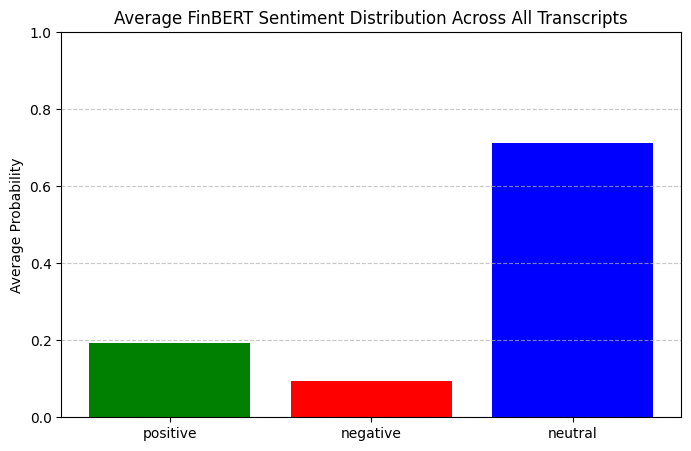


Average Sentiment Probabilities Across All Transcripts:
Positive: 0.194
Negative: 0.095
Neutral: 0.711


In [ ]:
# Redefine the analyze_and_visualize_sentiment function to return probabilities
def analyze_and_visualize_sentiment(text, max_length=512): # FinBERT max_length can only be 512
    # Tokenize the text with truncation and padding
    inputs = tokenizer(text, return_tensors="pt", truncation=True, padding="max_length", max_length=max_length)

    # Move inputs to the same device as the model
    device = model.device
    inputs = {key: val.to(device) for key, val in inputs.items()}


    # Get model outputs
    with torch.no_grad(): # Use no_grad as not training - FinBERT model being used is pre-trained
      outputs = model(**inputs)

    # Get probabilities
    probabilities = torch.softmax(outputs.logits, dim=1)[0]
    probs = probabilities.detach().cpu().numpy() # Move probabilities to CPU before converting to numpy

    # Return probabilities
    return probs

# Define label mapping (FinBERT: 0=positive, 1=negative, 2=neutral)
label_mapping = {0: "positive", 1: "negative", 2: "neutral"}
labels = [label_mapping[i] for i in range(3)]

# List to store sentiment probabilities for all transcripts
all_probs = []

# Analyze sentiment for each transcript and store probabilities
print("Analyzing sentiment for all transcripts...")
for i, transcript_text in enumerate(tqdm(all_transcripts_list, desc="Analyzing transcripts")):
    probs = analyze_and_visualize_sentiment(transcript_text)
    all_probs.append(probs)

# Convert the list of probabilities to a NumPy array for easier aggregation
all_probs_array = np.array(all_probs)

# Calculate the average probabilities across all transcripts
average_probs = np.mean(all_probs_array, axis=0)

# Visualize the average sentiment distribution using a bar plot
plt.figure(figsize=(8, 5))
plt.bar(labels, average_probs, color=['green', 'red', 'blue'])
plt.ylabel('Average Probability')
plt.title('Average FinBERT Sentiment Distribution Across All Transcripts')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Print the average probabilities
print("\nAverage Sentiment Probabilities Across All Transcripts:")
for label, avg_prob in zip(labels, average_probs):
    print(f"{label.capitalize()}: {avg_prob:.3f}")

Most of the sentiment identified was neutral, as would be expected in financial speak. But, of that identified as positive or negative there was more positivity. JPM is a financially stable bank and so this would be expected.

**Sentiment Intensity Analyzer**

Next, SIA was used because LLMs can over-predict texts as neutral because of "uncommon or nuanced terms." (Singh, 2024). This can be due to a limited dictionary. Also, it is predominantly the negative text we are interested in as this is most probably linked to risk. We thought this might provide indications as to what prompts to use with FinBERT too. However, the accuracy of SIA can be limited so it was used with caution.

In [ ]:
# Initialize analyzer
sia = SentimentIntensityAnalyzer()

def get_negative_words(transcripts):
    negative_words = set()
    for transcript in transcripts:
        words = transcript.split()
        for word in words:
            score = sia.polarity_scores(word)
            if score['compound'] < -0.3:  # Tune threshold if needed
                negative_words.add(word)
    return list(negative_words)

# Example usage
transcripts = [
    "The movie was terrible and boring.",
    "I hated the ending, it was awful.",
    "Not a fan of the gloomy soundtrack."
]

neg_words = get_negative_words(transcripts)
print("Negative words:", neg_words)

Negative words: ['awful.', 'hated', 'boring.', 'terrible']


SIA was identifying negative words well and so was used on the transcript data.

In [ ]:
# Identify negative words using SIA
sia = SentimentIntensityAnalyzer()
negative_words = []

for text in all_transcripts_list:
    for word in text.split():
        score = sia.polarity_scores(word)['compound']
        if score < -0.3:  # Use threshold of -0.3
            negative_words.append(word)

In [ ]:
# Show occurence of negative words
word_counts = Counter(negative_words)
word_counts.most_common()

[('losses', 697),
 ('loss', 175),
 ('excluded', 170),
 ('debt', 143),
 ('LOSS', 62),
 ('Debt', 40),
 ('recession', 40),
 ('Gross', 39),
 ('uncertainties', 38),
 ('LOSSES', 37),
 ('86', 35),
 ('gross', 29),
 ('negative', 27),
 ('Losses', 25),
 ('stress', 24),
 ('bad', 24),
 ('uncertainty', 22),
 ('worse', 20),
 ('war', 20),
 ('difficult', 17),
 ('unemployment', 16),
 ('lags', 14),
 ('187', 12),
 ('critical', 12),
 ('crisis', 11),
 ('wrong', 11),
 ('pressures', 11),
 ('troubled', 11),
 ('lose', 11),
 ('adverse', 11),
 ('suspended', 10),
 ('restricted', 10),
 ('lack', 9),
 ('problem', 8),
 ('Negative', 8),
 ('disruptions', 7),
 ('penalty', 7),
 ('aggressively', 6),
 ('waste', 6),
 ('Troubled', 6),
 ('imperfect', 6),
 ('problems', 6),
 ('182', 6),
 ('fraud', 6),
 ('worry', 6),
 ('lost', 5),
 ('hell', 5),
 ('argue', 5),
 ('lag', 5),
 ('severe', 5),
 ('pain', 5),
 ('shock', 4),
 ('warning', 4),
 ('turmoil', 4),
 ('mistake', 4),
 ('Stress', 3),
 ('depressed', 3),
 ('distraction', 3),
 ('troub

"War", "debt", "loss", and "recession" were amongst the negative words identified and therefore were used in prompts for FinBERT in our attempts to identify risk. Maual validation was limited but the negative words recognised were negative in context and it provided a fast and effective way to begin to identify risk in the data.

**FinBERT - tone analyser**

The FinBERT tone analyser “yiyanghkust/finbert-tone” was used to analyse emotional tone as it is pre-tuned to capture nuances in financial analysis that general sentiment analysis models might miss (Sener, 2023). It was also able to score insights for PRA analysts to proritise risk mitigation.

In [ ]:
# Load FinBERT model and tokenizer
model_name = "yiyanghkust/finbert-tone"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name)

# Function to get sentiment score for each token
def get_token_sentiments(text):
    tokens = text.split()
    negative_tokens = []

    for i, token in enumerate(tokens):
        input_text = ' '.join(tokens[max(i - 2, 0): i + 3])  # Use a sliding window
        inputs = tokenizer(input_text, return_tensors="pt", truncation=True)
        with torch.no_grad():
            outputs = model(**inputs)
            scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
            label = torch.argmax(scores).item()
            label_str = model.config.id2label[label]

            if label_str.lower() == 'negative':
                negative_tokens.append((token, scores[0][label].item()))

    return negative_tokens

# Check with example usage
text = "The company suffered huge losses but expects a strong recovery."
negative_words = get_token_sentiments(text)

# Print negative tokens and their confidence scores
for word, score in negative_words:
    print(f"Negative word: {word} (confidence: {score:.2f})")

config.json:   0%|          | 0.00/533 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/439M [00:00<?, ?B/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Negative word: The (confidence: 1.00)
Negative word: company (confidence: 1.00)
Negative word: suffered (confidence: 1.00)
Negative word: huge (confidence: 1.00)
Negative word: but (confidence: 0.97)


The model was overly classifying tokens as negative and so a weighted strategy was used so classification was based on the whole sentence, not just individual tokens.

In [ ]:
# Check label integers
model.config.id2label

{0: 'Neutral', 1: 'Positive', 2: 'Negative'}

In [ ]:
# Reverse integers so they make more sense (0: 'Negative', 1: 'Positive', 2: 'Neutral')
label2id = {v.lower(): k for k, v in model.config.id2label.items()}

In [ ]:
# Prepare inputs for the model
inputs = tokenizer(text, return_tensors="pt", truncation=True) # Use the text variable defined earlier

# Get model outputs
with torch.no_grad(): # Use no_grad as not training
    outputs = model(**inputs)

# Calculate scores using the newly defined outputs
scores = torch.nn.functional.softmax(outputs.logits, dim=-1)
negative_score = scores[0][label2id['negative']].item()

print(f"Negative score: {negative_score}") # Print the score to verify

Negative score: 0.12080474197864532


This is a sensible score for the test sentence, and so the model was run on all of the transcript text.

In [ ]:
batch_size = 32 # Run in batches to reduce RAM used
data = []

# Loop through batches
for i in tqdm(range(0, len(JPM_df_sentences), batch_size), desc="Scoring sentences"):
    batch_sentences = JPM_df_sentences.iloc[i:i+batch_size]

    inputs = tokenizer(
        batch_sentences["sentence"].tolist(),
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=512
    )

    with torch.no_grad():
        outputs = model(**inputs)

    scores = torch.nn.functional.softmax(outputs.logits, dim=-1)

    for j, s in enumerate(scores):
        data.append({
            "quarter": batch_sentences.iloc[j]["quarter"],
            "year": batch_sentences.iloc[j]["year"],
            "document_type": batch_sentences.iloc[j]["document_type"],
            "sentence": batch_sentences.iloc[j]["sentence"],
            "negative_score": s[label2id['negative']].item(),
            "neutral_score": s[label2id['neutral']].item(),
            "positive_score": s[label2id['positive']].item()
        })

# Create final DataFrame
JPM_df_sentences = pd.DataFrame(data)
print(JPM_df_sentences.head())

Scoring sentences: 100%|██████████| 424/424 [2:42:15<00:00, 22.96s/it]

  quarter  year     document_type  \
0      Q1  2023  Earnings Release   
1      Q1  2023  Earnings Release   
2      Q1  2023  Earnings Release   
3      Q1  2023  Earnings Release   
4      Q1  2023  Earnings Release   

                                            sentence  negative_score  \
0         1Q23 Financial Results April 14, 2023 1Q23        0.000297   
1                             Financial highlights 1        0.000091   
2  See note 3 on slide 10 2 Represents the estima...        0.000076   
3  See note 1 on slide 11 3 Standardized risk-wei...        0.000042   
4                  Estimated for the current period.        0.000052   

   neutral_score  positive_score  
0       0.999634        0.000069  
1       0.053385        0.946524  
2       0.999880        0.000043  
3       0.999954        0.000004  
4       0.999942        0.000006  


In [ ]:
# Extract all sentences with negative score greater than 0.05
# Change JPM_df to JPM_df_sentences to access the sentiment scores
negative_sentences_df = JPM_df_sentences[JPM_df_sentences['negative_score'] > 0.05]

# Display the filtered DataFrame
print(negative_sentences_df)

      quarter  year     document_type  \
38         Q1  2023  Earnings Release   
41         Q1  2023  Earnings Release   
112        Q1  2023  Earnings Release   
193        Q1  2023  Earnings Release   
283        Q1  2021  Earnings Release   
...       ...   ...               ...   
13357      Q1  2023  Earnings Release   
13394      Q1  2023  Earnings Release   
13442      Q1  2023  Earnings Release   
13445      Q1  2023  Earnings Release   
13528      Q1  2023  Earnings Release   

                                                sentence  negative_score  \
38     Net interest income was $1.7B, compared with ...        0.923594   
41     MARKETS SIGNIFICANT SOURCES OF UNCERTAINTY ~$8...        0.431573   
112           Absorbing Capacity for the current period.        0.089265   
193    Excluding these significant items resulted in ...        0.999915   
283    Average VaR ($mm)7 $41 $99 $127 Commercial Ban...        0.058126   
...                                                

In [ ]:
# Export negative_sentences_df as a csv
negative_sentences_df.to_csv('negative_sentences.csv', index=False)

**Manual validation**

"Negative" sentences clearly related to data risk, financial resilience and operational resilience were identified. These were appropriately ranked according to the intensity of the negative sentiment.

The analysis picked up difficulties with:-

*   The war in Ukraine and relationships with China - data risk and operational resilience
*   Housing is in short supply in America - financial stressor
*   "It does affect capital a little bit" - financial resilience (expressed by an executive, so the model picked up negativity in executive speak)
*   We are in for a couple of years of sub-target returns - financial resilience

It also recognised key words as negative, which could perhaps have been difficult to classify:-

*   rapidly
*   dramatically

Neutral/positive statements which could be difficult to classify were also suitably classified. For example:-

*   As expected, the macro franchise substantially normalized from last year's elevated levels of volatility and client flows
*   If you're competing with JPMorgan that could be pretty tough competition

However, there were some false negatives, particularly in the lower ranking negative sentences. For example, “So the top two banks have about 50% consumer market share, loan-to-deposit ratios are low." Where a low loan-to-deposit ratio is generally positive.








In [ ]:
# Filter positive sentences with score > 0.05
# Change JPM_df to JPM_df_sentences
positive_sentences_df = JPM_df_sentences[JPM_df_sentences['positive_score'] > 0.05][['sentence', 'positive_score']]

# Sort for better viewing
positive_sentences_df = positive_sentences_df.sort_values(by='positive_score', ascending=False)

# Display neatly in the console
print(positive_sentences_df.to_string(index=False))

In [ ]:
# Export positive sentences as a csv
positive_sentences_df.to_csv('positive_sentences.csv', index=False)

In [ ]:
# Separate out all negative results from "analysts"
# Change negative_sentences_df_subset to the correct DataFrame JPM_df_sentences
negative_sentences_df_subset_analyst = negative_sentences_df[negative_sentences_df['sentence'].str.contains('analyst', case=False)]

# Show DataFrame
print(negative_sentences_df_subset_analyst)

# Give shape of negative analyst DataFrame
negative_sentences_df_subset_analyst.shape

                                                                                                                                                                                                                                                                                                                                                   sentence  \
8041                                                                                                                                                                                                                                                                           Steven Chubak Analyst, Wolfe Research LLC Q ...elevated macro uncertainties.   
7140                                                                                                                                                  And if you hold the balance sheet steady, you're talking about a -basis point  Charles W. Peabody Analyst, Portales Partners LLC Q drop in your marg

(15, 2)

In [ ]:
# Separate out all positive results from "analysts"
# Change positive_sentences_df_subset to the correct DataFrame JPM_df_sentences
positive_sentences_df_subset_analyst = positive_sentences_df[positive_sentences_df['sentence'].str.contains('analyst', case=False)]

# Show DataFrame
print(positive_sentences_df_subset_analyst)

                                                                                                                   sentence  \
11775                                                          Gerard Cassidy Analyst, RBC Capital Markets LLC Q Very good.   
4805                                                           Gerard Cassidy Analyst, RBC Capital Markets LLC Q Very good.   
4834                                                           Gerard Cassidy Analyst, RBC Capital Markets LLC Q Very good.   
6722                                                           Gerard Cassidy Analyst, RBC Capital Markets LLC Q Very good.   
1425                                                           Gerard Cassidy Analyst, RBC Capital Markets LLC Q Very good.   
...                                                                                                                     ...   
12892  Steven Chubak Analyst, Wolfe Research LLC Q Thanks for clarifying that and for not punting on the topic 

Analyst speak was more positive than negative, and mostly neutral. This would be expected for JPMorgan where positive earnings reports, successful strategic interventions and strong financial results are the norm.

**Prompting FinBERT**

FinBERT was prompted to determine sentiment classification accuracy according to JPMorgan overall stability and global events between Q1 2021 - Q2 2023. Prompt engineering was done by using output of the previous models throughout the experiments, and using key events in the bank's history.


--- Topic: Financial Stress ---


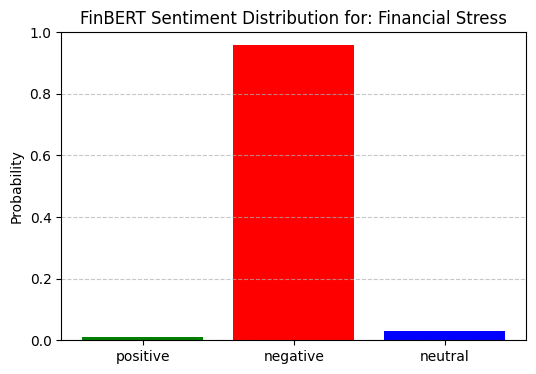

Sentiment Probabilities for 'Financial Stress':
Positive: 0.010
Negative: 0.960
Neutral: 0.030

--- Topic: Recession ---


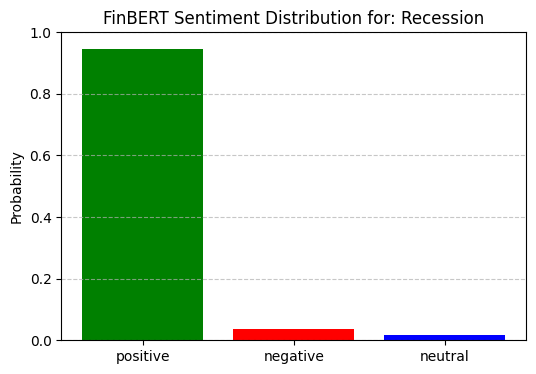

Sentiment Probabilities for 'Recession':
Positive: 0.944
Negative: 0.038
Neutral: 0.018

--- Topic: Losses ---


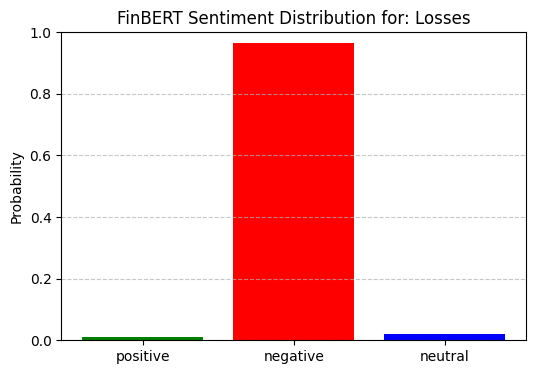

Sentiment Probabilities for 'Losses':
Positive: 0.012
Negative: 0.967
Neutral: 0.022

--- Topic: Debt ---


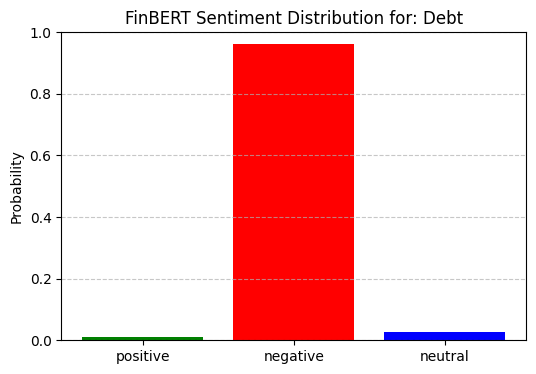

Sentiment Probabilities for 'Debt':
Positive: 0.011
Negative: 0.962
Neutral: 0.027

--- Topic: Mergers ---


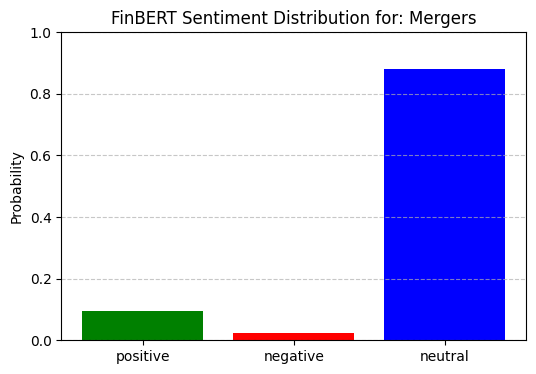

Sentiment Probabilities for 'Mergers':
Positive: 0.095
Negative: 0.023
Neutral: 0.882


In [ ]:
topics = {
    "Financial Stress": "The war in Ukraine has caused tensions and financial stress.", # War started on 24th February 2022
    "Recession": "Recovery from the COVID-caused recession has been good.", # Test entry (no recession in quarters analysed - will FinBERT recognise this?)
    "Losses": "Net losses in 2021 have resulted in financial instability because of reduced lender resilience.", # JPMorgan experienced losses in Q1 2021 and Q2 2021 but then strong profitability and growth in Q2 2023
    "Debt": "The debt-to-equity ratio decreased in 2023.", # Lower debt-to-equity ratio is positive
    "Mergers": "Mergers are probable in the coming fiscal year." # JPMorgan merged with Bank One in 2024 and First Republic Bank in 2023. These have been positive for JPMorgan.
}

# Define label mapping (FinBERT: 0=positive, 1=negative, 2=neutral)
label_mapping = {0: "positive", 1: "negative", 2: "neutral"}
labels = [label_mapping[i] for i in range(3)]

# Analyze each topic and plot sentiment
for topic, text in topics.items():
    print(f"\n--- Topic: {topic} ---")

    # Analyze sentiment and get probabilities
    probs = analyze_and_visualize_sentiment(text)

    # Visualize the sentiment distribution using a bar plot for the single topic
    plt.figure(figsize=(6, 4))
    plt.bar(labels, probs, color=['green', 'red', 'blue'])
    plt.ylabel('Probability')
    plt.title(f'FinBERT Sentiment Distribution for: {topic}')
    plt.ylim(0, 1)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()

    # Optional: Print the probabilities for the topic
    print(f"Sentiment Probabilities for '{topic}':")
    for label, prob in zip(labels, probs):
        print(f"{label.capitalize()}: {prob:.3f}")

All outcomes were as would be expected except for debt. The reduction in debt-to-equity ratio was a positive occurrence. The sentiment of the prompt can also influence the sentiment classification with FinBERT. Although the outcome of these experiments demosntrates the robustness of these tools, fine-tuning using a labelled dataset is needed, if this aspect of our Bank of England project were to be taken to a further level.

*Now please got to Market Research Part 2 for the Credit Suisse "stress test", results, a comparison of JPM and CS output, conclusions, and references.*